# 20 — Zero-level offsets as fit parameters (plots for Phil)

**Question (from a collaborator).** Should the spectral fit include additive zero-level offsets? The TRIS II paper's
Table 3 gives systematic uncertainties much larger than the statistical ones. Phil confirmed these are most likely on
the **zero level**. A zero-level error is one number for a whole survey, so it should enter the fit as a **parameter**
with a Gaussian prior whose width is the quoted systematic, not as an extra random error added in quadrature at every
point (which is what the SED fits do now). This notebook tests that and shows what changes.

**The model.** At each ring sample $i$ the sky is a power law (or, in a second configuration, a curved power law):

$$T_i(\nu) = A_i\,(\nu/408\ \mathrm{MHz})^{\beta_i}\ \big[\times\,e^{C_i \ln^2(\nu/408)}\big].$$

Each survey $k$ with a quoted zero-level uncertainty gets **one** additive offset $o_k$, **shared by all ring samples**:

$$T^{\rm meas}_{k,i} = T_i(\nu_k) + o_k + n_{k,i}, \qquad o_k \sim \mathcal N(0,\ \sigma_{{\rm zl},k}^2),$$

where the noise $n_{k,i}$ has the survey's error **without** its zero-level term (scale and noise terms kept), so the
zero level is not counted twice. The fit is the maximum a posteriori point of

$$F(\mathbf o) = \sum_{i\ \rm unmasked} \min_{A_i,\beta_i[,C_i]} \chi^2_i(\mathbf o) + \sum_k (o_k/\sigma_{{\rm zl},k})^2 ,$$

with the per-sample fits nested inside (a few parameters each) and only the shared offsets in the outer minimisation.
No nested sampling.

**Configurations.** (1) power law, offsets on every survey with a quoted zero level; (2) power law, offsets on TRIS only;
(3) curved power law, offsets as (1); (4) the baseline: no offsets, errors as they are now. Two references are added so
that every χ² change can be read: the baseline curved power law, and both models with the zero-level terms removed and
the offsets held at 0.

**Data.** The six ring surveys of the SED fits: TRIS 600 and 820 (ring data), LWA1 35, Maipu 45, LWA1 80, Stockert 1420
(TRIS-beam ring TODs). As in notebook 14, the surveys come from notebook 18's **beam-matched** TODs
(`USE_BEAM_MATCHED = True`) with their errors rebuilt from their components, and TRIS from notebook 12's fit cache
(`model_comparison/sky_models_408/cache/fits/unitNNN__power_law.npz`, keys `nu`, `t`, `s`). That cache was made before
beam matching (2026-10-23), so its survey points are the older native-resolution TODs; `USE_BEAM_MATCHED = False` uses
them instead. Cygnus A is masked everywhere: RA 299.9 ± 25°.

> **⚠ All σ are underestimates.** The ring samples are 3° apart under a ~20° beam, so there are only about
> 360°/20° ≈ 18 independent samples, not ~100. Errors from the Hessian are therefore too small by roughly
> √(120/18) ≈ 2.6; both are reported.

**Inputs** (read only): notebook 12's cache, notebook 18's `beam_matched_tods.npz`, `src/moonrunes/sed_prototype.py`
(`PUBLISHED_ERRORS`, `ring_sigma`), `model_comparison/error_bars.csv`, the TRIS archive (through limTOD) and
`inputs_audit/inputs_audit.md`. **Outputs:** figures and CSVs in `model_comparison/zero_level_offsets/`; the profile
fits are cached in its `cache/`. Rerun: Restart & Run All (a few minutes without the cache, seconds with it).

In [1]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import re
import json
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from scipy.optimize import minimize

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_CACHE = REPO / "model_comparison" / "sky_models_408" / "cache"    # notebook 12's cache, read only
BM_FILE = REPO / "model_comparison" / "beam_matched_tods" / "beam_matched_tods.npz"   # notebook 18, read only
ERRORS_CSV = REPO / "model_comparison" / "error_bars.csv"
AUDIT_MD = REPO / "inputs_audit" / "inputs_audit.md"
OUT_DIR = REPO / "model_comparison" / "zero_level_offsets"
CACHE_DIR = OUT_DIR / "cache"
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"
# Beam matching (notebook 18): survey and Haslam ring TODs made with the pipeline's beam-matching kernel, as notebook 14.
USE_BEAM_MATCHED = True

# The six ring surveys, low frequency first.  key -> label; keys as in the fit cache.
SURVEYS = {"LWA_35MHz.fits": "LWA1 35", "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA1 80",
           "TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420"}

# Cygnus A mask, applied everywhere
CYG_A_RA = 299.9
MASK_HALF_WIDTH = 25.0     # deg

# Prior width of each survey's shared zero-level offset, in K.  None = no offset for that survey.
#   TRIS: the zero-level uncertainties dT_zero of TRIS II Table 3 ("Accuracy of the absolute measurements of T_sky
#         performed by TRIS at dec = +42 deg"): 66 mK at 0.60 GHz; +430 / -300 mK at 0.82 GHz.  The prior is a
#         symmetric Gaussian, so 820 MHz uses the larger side, 0.430 K (as ring_sigma does).  Table 3 footnote a: the
#         0.82 GHz zero-level uncertainty from the absolute calibration alone is 0.659 K; the quoted +430 / -300 mK
#         comes after an astrophysical assumption on the Galactic signal (Paper III, section 3).  Not used here.
#         (2.5 GHz, 284 mK, is not one of the six surveys.)  If set to None, the fit falls back to the zero-level term
#         inside ring_sigma and prints a warning.
#   Other surveys: their published zero-level uncertainty, sed_prototype.PUBLISHED_ERRORS[...]["zero_k"] (set below);
#         a survey that quotes none (zero_k = 0) gets no offset.
ZERO_LEVEL_SIGMA_K = {
    "TRIS_600": 0.066,     # TRIS II Table 3, 0.60 GHz: dT_zero = 66 mK
    "TRIS_820": 0.430,     # TRIS II Table 3, 0.82 GHz: dT_zero = +430 / -300 mK, larger side (footnote a: 659 mK)
    "LWA_35MHz.fits": "published",
    "MAIPU_45mhZ.fits": "published",
    "LWA_80MHz.fits": "published",
    "STOCKERT_VILLA_1400MHZ.fits": "published",
}
# Map-making zero levels (z-hat) for reference only; a different route (stage 1 maps), read from inputs_audit.md.
ZHAT_EXPECTED = {"TRIS_600": (1.737, 0.043), "TRIS_820": (0.516, 0.027)}

N_INDEP = 18                                   # independent beams on the ring, 360 deg / ~20 deg
PROFILE_POINTS = 41                            # grid points per 1-D profile
TIE = 2.0                                      # |Δχ²| <= 2 (|Δ ln L| <= 1): power law and curved PL indistinguishable
REP_RA = [0.0, 120.0, 240.0]                   # Figure B: the unmasked samples nearest these RAs

with open(REPO / "model_comparison" / "config.yaml") as f:
    NU0 = float(yaml.safe_load(f)["models"]["nu0_mhz"])     # 408 MHz

# Okabe-Ito, colourblind-safe, one colour per configuration
CFG_COL = {"baseline": "#000000", "offsets": "#0072B2", "TRIS only": "#E69F00", "curved": "#882255", "reference": "#7F7F7F"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 24, "axes.titlesize": 24,
                     "axes.labelsize": 24, "legend.fontsize": 20, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

## 1. The data and how each error is built

**How the per-point errors are made now** (read from `sed_prototype.py` and `error_bars.csv`):

* **TRIS** (`ring_sigma`): the archive's per-sample statistical error (zeros floored to the smallest positive value)
  ⊕ the archive's published zero-level uncertainty (0.066 K at 600 MHz; at 820 MHz the larger side of +0.43 / −0.30 K).
* **Surveys** (`sigma_for`, kind `published` in `error_bars.csv`): scale × |T| ⊕ zero level ⊕ rms noise, with the values
  of `PUBLISHED_ERRORS` (the CSV and the dictionary are checked against each other below).

All are added in quadrature and treated as independent per point. The cell splits each into (a) statistical / noise,
(b) scale and (c) zero level, and checks that the three rebuild the cached total. **LWA1 35 and 80 quote no separate
zero level** (Dowell et al. 2017 give one 15–25% calibration accuracy "for both structure and sky-averaged temperature"),
so their zero-level term cannot be separated: they keep their whole error and get no offset.

In [2]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(REPO / "model_comparison"))
for _name in [n for n in sys.modules if n.split(".")[0] in ("moonrunes", "models", "run_comparison")]:
    del sys.modules[_name]
from moonrunes.config import load_config
from moonrunes.sed_prototype import PUBLISHED_ERRORS, ring_sigma, sigma_for
from moonrunes.stage1_tris_maps import import_limtod_tris
import run_comparison as rc                       # read_error_bars only

KEYS = list(SURVEYS)
RA = np.load(SRC_CACHE / "ring_ra.npy")
N = RA.size

# ---- the cached points (notebook 12) ----
T = {k: np.full(N, np.nan) for k in KEYS}
S_CACHE = {k: np.full(N, np.nan) for k in KEYS}
FREQ = {}
for u in range(N):
    r = np.load(SRC_CACHE / "fits" / f"unit{u:03d}__power_law.npz", allow_pickle=False)
    for k, nu, t, s in zip((str(x) for x in r["keys"]), r["nu"], r["t"], r["s"]):
        T[k][u], S_CACHE[k][u], FREQ[k] = t, s, float(nu)
T_CACHED = {k: v.copy() for k, v in T.items()}

# ---- error components ----
config = load_config(REPO / "configs" / "run_config.yaml")
tris = import_limtod_tris(config)
archive = config.resolve_path("paths.tris_archive_dir")
csv_rows = rc.read_error_bars(ERRORS_CSV)
NOISE, SCALE_FRAC, ZL = {}, {}, {}
for k in KEYS:
    if k.startswith("TRIS_"):
        ring = tris.read_tris_ring(archive / f"TRIS_absolute_{k[5:]}.txt")
        assert np.allclose(np.asarray(ring.ra_deg), RA)
        stat = np.asarray(ring.statistical_uncertainty_k, dtype=float)
        NOISE[k] = np.where(stat > 0, stat, stat[stat > 0].min())        # as ring_sigma floors it
        z = ring.zero_level_uncertainty_k
        ZL[k] = float(z) if np.isscalar(z) else max(z.positive_k, z.negative_k)
        SCALE_FRAC[k] = 0.0
        assert np.allclose(np.hypot(NOISE[k], ZL[k]), ring_sigma(ring)), k
    else:
        row, pub = csv_rows[k], PUBLISHED_ERRORS[k]
        assert row["kind"] == "published", k
        vals = (float(row["scale_frac"]), float(row["zero_level_k"]), float(row["noise_k"]))
        assert np.allclose(vals, (pub["scale"], pub["zero_k"], pub["noise_k"])), (k, vals, pub)   # CSV == dictionary
        SCALE_FRAC[k], ZL[k], NOISE[k] = vals[0], vals[1], np.full(N, vals[2])

def total_sigma(k, t, with_zl=True):
    """The per-point error of survey k at temperatures t, with or without its zero-level term."""
    return np.sqrt(NOISE[k] ** 2 + (SCALE_FRAC[k] * t) ** 2 + (ZL[k] ** 2 if with_zl else 0.0))

for k in KEYS:     # the components rebuild the cached totals exactly
    assert np.allclose(total_sigma(k, T_CACHED[k]), S_CACHE[k], rtol=1e-9), k

# ---- beam-matched survey TODs and Haslam (notebook 18), as notebook 14 ----
if USE_BEAM_MATCHED:
    zb = np.load(BM_FILE, allow_pickle=False)
    assert np.allclose(zb["ra_deg"], RA)
    for k in KEYS:
        if not k.startswith("TRIS_"):
            T[k] = np.asarray(zb[f"survey::{k}"], dtype=float)
    T_H = np.asarray(zb[f"survey::{HASLAM_FILE}"], dtype=float)
    print("surveys and Haslam: beam-matched ring TODs (notebook 18); TRIS: ring data. Largest change from the cached "
          "native TODs: " + ", ".join(f"{SURVEYS[k]} {100 * np.nanmax(np.abs(T[k] / T_CACHED[k] - 1)):.1f}%"
                                         for k in KEYS if not k.startswith("TRIS_")))
else:
    zs = np.load(SRC_CACHE / "sky_tods.npz", allow_pickle=False)
    assert str(zs["names"][0]) == "Haslam (uncorrected)"
    T_H = np.where(zs["cov_0"] >= 0.5, zs["tod_0"], np.nan)
    print("surveys and Haslam: the cached native-resolution TODs (USE_BEAM_MATCHED = False)")
S_H = np.asarray(sigma_for(dict(freq_mhz=408.0, file=HASLAM_FILE), T_H), dtype=float)
S_TOT = {k: total_sigma(k, T[k]) for k in KEYS}             # the errors as the SED fits use them
S_NOZL = {k: total_sigma(k, T[k], with_zl=False) for k in KEYS}

# ---- the Cygnus mask ----
d_cyg = np.abs((RA - CYG_A_RA + 180.0) % 360.0 - 180.0)
KEEP = (d_cyg > MASK_HALF_WIDTH) & np.all([np.isfinite(T[k]) for k in KEYS], axis=0)
IDX = np.flatnonzero(KEEP)
NS = IDX.size
print(f"{NS} of {N} ring samples used (RA {CYG_A_RA - MASK_HALF_WIDTH:g}–{CYG_A_RA + MASK_HALF_WIDTH:g}° masked)\n")

comp = pd.DataFrame([{"survey": SURVEYS[k], "ν [MHz]": FREQ[k],
                      "(a) noise, median [K]": np.median(NOISE[k][KEEP]),
                      "(b) scale": f"{100 * SCALE_FRAC[k]:g}% → {np.median(SCALE_FRAC[k] * T[k][KEEP]):.3g} K",
                      "(c) zero level [K]": ZL[k] if ZL[k] > 0 else "none quoted",
                      "total, median [K]": np.median(S_TOT[k][KEEP]),
                      "zero level's share of σ² [%]": 100 * np.median(ZL[k] ** 2 / S_TOT[k][KEEP] ** 2)}
                     for k in KEYS])
comp.to_csv(OUT_DIR / "error_components.csv", index=False)
print(comp.round(4).to_string(index=False))

surveys and Haslam: beam-matched ring TODs (notebook 18); TRIS: ring data. Largest change from the cached native TODs: LWA1 35 0.0%, Maipu 45 0.0%, LWA1 80 0.0%, Stockert 1420 0.0%
103 of 120 ring samples used (RA 274.9–324.9° masked)

       survey  ν [MHz]  (a) noise, median [K]        (b) scale (c) zero level [K]  total, median [K]  zero level's share of σ² [%]
      LWA1 35     35.0                  0.000 20% → 2.77e+03 K        none quoted          2771.0992                        0.0000
     Maipu 45     45.0                  0.000     1.7% → 124 K               39.0           129.8048                        9.0271
      LWA1 80     80.0                  0.000      20% → 395 K        none quoted           395.0527                        0.0000
     TRIS 600    600.5                  0.009         0% → 0 K              0.066             0.0666                       98.1744
     TRIS 820    817.8                  0.010         0% → 0 K               0.43             0.4301         

### The prior widths

From `ZERO_LEVEL_SIGMA_K`. A survey gets an offset only if it has a prior width; for it, the zero-level term is
removed from its per-point error. The TRIS widths are the zero-level uncertainties of TRIS II Table 3: 0.066 K at
600 MHz, and 0.430 K at 820 MHz (the larger side of +0.430 / −0.300 K, used as a symmetric Gaussian; Table 3's
footnote a gives 0.659 K from the absolute calibration alone, before an astrophysical assumption on the Galactic signal,
which is not used here). The next cell checks that these equal the zero-level terms already inside `ring_sigma`.

In [3]:
PRIOR = {}                       # survey -> prior width (K), only for surveys that get an offset
PRIOR_SOURCE = {}
TABLE3 = {k: ZERO_LEVEL_SIGMA_K[k] for k in ("TRIS_600", "TRIS_820")}
for k in KEYS:
    v = ZERO_LEVEL_SIGMA_K[k]
    if k.startswith("TRIS_"):
        if v is None:
            PRIOR[k], PRIOR_SOURCE[k] = ZL[k], "FALLBACK: zero-level term in ring_sigma (TRIS II Table 3 not filled in)"
        else:
            PRIOR[k], PRIOR_SOURCE[k] = float(v), "TRIS II Table 3"
    elif v == "published":
        if ZL[k] > 0:
            PRIOR[k], PRIOR_SOURCE[k] = ZL[k], "PUBLISHED_ERRORS zero_k"
        else:
            PRIOR_SOURCE[k] = "none quoted: zero level cannot be separated; whole error kept, no offset"
    elif v is not None:
        PRIOR[k], PRIOR_SOURCE[k] = float(v), "ZERO_LEVEL_SIGMA_K"
    else:
        PRIOR_SOURCE[k] = "no offset (ZERO_LEVEL_SIGMA_K is None)"

# check: the Table 3 values against the zero-level terms inside ring_sigma
for k in TABLE3:
    if TABLE3[k] is not None:
        same = np.isclose(float(TABLE3[k]), ZL[k], rtol=0, atol=1e-12)
        print(f"{SURVEYS[k]}: TRIS II Table 3 {float(TABLE3[k]):.3f} K, zero-level term in ring_sigma {ZL[k]:.3f} K -> "
              + ("MATCH" if same else f"DO NOT MATCH (difference {float(TABLE3[k]) - ZL[k]:+.3g} K)"))
print()

if any(TABLE3[k] is None for k in TABLE3):
    print("!" * 100)
    print("!!  WARNING: TRIS II Table 3 is NOT filled in (ZERO_LEVEL_SIGMA_K['TRIS_600'] / ['TRIS_820'] are None).")
    print("!!  The TRIS offset priors fall back to the archive's zero-level terms in ring_sigma:")
    for k in TABLE3:
        if TABLE3[k] is None:
            print(f"!!      {SURVEYS[k]}: {ZL[k]:.3f} K")
    print("!!  Every TRIS result below uses these fallback widths, NOT the Table 3 systematics.")
    print("!" * 100)

OFF_ALL = [k for k in KEYS if k in PRIOR]
OFF_TRIS = [k for k in OFF_ALL if k.startswith("TRIS_")]
SIG = np.array([PRIOR.get(k, np.nan) for k in KEYS])
print(pd.DataFrame({"survey": [SURVEYS[k] for k in KEYS],
                    "offset prior σ [K]": [PRIOR.get(k, np.nan) for k in KEYS],
                    "source": [PRIOR_SOURCE[k] for k in KEYS]}).to_string(index=False))
print("\nsurveys with an offset:", ", ".join(SURVEYS[k] for k in OFF_ALL))

TRIS 600: TRIS II Table 3 0.066 K, zero-level term in ring_sigma 0.066 K -> MATCH
TRIS 820: TRIS II Table 3 0.430 K, zero-level term in ring_sigma 0.430 K -> MATCH

       survey  offset prior σ [K]                                                                   source
      LWA1 35                 NaN none quoted: zero level cannot be separated; whole error kept, no offset
     Maipu 45              39.000                                                  PUBLISHED_ERRORS zero_k
      LWA1 80                 NaN none quoted: zero level cannot be separated; whole error kept, no offset
     TRIS 600               0.066                                                          TRIS II Table 3
     TRIS 820               0.430                                                          TRIS II Table 3
Stockert 1420               0.500                                                  PUBLISHED_ERRORS zero_k

surveys with an offset: Maipu 45, TRIS 600, TRIS 820, Stockert 1420


## 2. The fit

`inner_fit` fits every unmasked sample at once (a vectorised Levenberg–Marquardt in the parameters ln A, β [, C],
on T itself with the given σ): the same minimum-χ² fit as `model_comparison/models.py`'s power law and curved power law,
checked below against `run_comparison.max_likelihood` (the maximum-likelihood helper of notebook 11 and the comparison).
Each evaluation fits every sample from both the previous solution and a fresh start and keeps the better, so F does not depend on the search path. `F` is the outer objective of the introduction; the offsets are searched in units of their prior widths, within ±10 of them (`U_MAX`). The scale
term of each survey's σ is computed from its measured temperature and kept fixed while the offsets move.

In [4]:
NU = np.array([FREQ[k] for k in KEYS])
X = np.log(NU / NU0)
T_DATA = np.stack([T[k][IDX] for k in KEYS], axis=1)          # (NS, 6)
S_TOT_M = np.stack([S_TOT[k][IDX] for k in KEYS], axis=1)
S_NOZL_M = np.stack([S_NOZL[k][IDX] for k in KEYS], axis=1)
MODEL_NPAR = {"power law": 2, "curved power law": 3}
U_MAX = 10.0                     # offsets are searched within ±10 prior widths

def inner_fit(t, s, npar, p0=None, n_iter=500, tol=1e-11):
    """Minimum chi^2 of T = exp(lnA + beta x [+ C x^2]) at every sample (rows of t, s).  Returns p, chi2, cov."""
    w = 1.0 / s ** 2
    V = np.stack([np.ones_like(X), X, X ** 2][:npar], axis=1)            # (npts, npar)
    if p0 is None or not np.all(np.isfinite(p0)):      # weighted straight line in log T
        lt = np.log(np.clip(t, 1e-300, None)); wl = (np.clip(t, 1e-300, None) / s) ** 2
        p = np.linalg.solve(np.einsum("ni,sn,nj->sij", V, wl, V), np.einsum("ni,sn,sn->si", V, wl, lt)[..., None])[..., 0]
    else:
        p = p0.copy()
    def chi2_of(p):
        m = np.exp(p @ V.T)
        return np.sum(w * (t - m) ** 2, axis=1), m
    c, m = chi2_of(p)
    lam = np.full(t.shape[0], 1e-3)
    eye = np.eye(npar)
    for _ in range(n_iter):
        J = m[:, :, None] * V[None]
        JTJ = np.einsum("sni,sn,snj->sij", J, w, J)
        g = np.einsum("sni,sn,sn->si", J, w, t - m)
        d = np.linalg.solve(JTJ + lam[:, None, None] * JTJ * eye, g[..., None])[..., 0]
        cn, mn = chi2_of(p + d)
        better = cn <= c
        p[better] += d[better]; m[better] = mn[better]
        dc = np.where(better, c - cn, 0.0); c = np.where(better, cn, c)
        lam = np.where(better, lam * 0.3, lam * 10.0).clip(1e-12, 1e12)
        if np.all((np.abs(d).max(axis=1) < tol) | (better & (dc < 1e-13 * np.maximum(c, 1.0)))):
            break
    J = m[:, :, None] * V[None]
    cov = np.linalg.pinv(np.einsum("sni,sn,snj->sij", J, w, J))
    return p, c, cov

CONFIGS = {   # name: (model, surveys whose zero-level term is removed from σ, surveys with a free offset)
    "(4) baseline: power law, errors as now":          ("power law", [], []),
    "baseline curved power law, errors as now":         ("curved power law", [], []),
    "reference: power law, zero levels removed, o = 0": ("power law", OFF_ALL, []),
    "reference: curved PL, zero levels removed, o = 0": ("curved power law", OFF_ALL, []),
    "(1) power law, offsets on all":                    ("power law", OFF_ALL, OFF_ALL),
    "(2) power law, offsets on TRIS only":              ("power law", OFF_TRIS, OFF_TRIS),
    "(3) curved power law, offsets on all":             ("curved power law", OFF_ALL, OFF_ALL),
}
BASE, BASE_C = "(4) baseline: power law, errors as now", "baseline curved power law, errors as now"
REF, REF_C = "reference: power law, zero levels removed, o = 0", "reference: curved PL, zero levels removed, o = 0"
C1, C2, C3 = "(1) power law, offsets on all", "(2) power law, offsets on TRIS only", "(3) curved power law, offsets on all"

class Problem:
    """F(u) for one configuration; u = offsets in units of their prior widths (free surveys only)."""
    def __init__(self, name):
        self.name = name
        self.model, reduced, self.free = CONFIGS[name]
        self.npar = MODEL_NPAR[self.model]
        self.s = np.where([k in reduced for k in KEYS], S_NOZL_M, S_TOT_M)
        self.cols = [KEYS.index(k) for k in self.free]
        self.sig = np.array([PRIOR[k] for k in self.free])
        self.p = None
    def offsets(self, u):
        o = np.zeros(len(KEYS)); o[self.cols] = np.asarray(u) * self.sig
        return o
    def fit(self, u):
        """Per-sample fits at offsets u: from the previous solution (warm) and from a fresh log-space start, keeping
        the lower chi^2 at each sample, so that F depends only on u and not on the path the search took."""
        t = T_DATA - self.offsets(u)
        p, c, cov = inner_fit(t, self.s, self.npar, None)
        if self.p is not None and np.all(np.isfinite(self.p)):
            pw, cw, covw = inner_fit(t, self.s, self.npar, self.p)
            w = cw < c
            p[w], c[w], cov[w] = pw[w], cw[w], covw[w]
        self.p = p
        return p, c, cov
    def F(self, u):
        u = np.asarray(u, float)
        if np.any(np.abs(u) > U_MAX):
            return 1e30
        p, c, _ = self.fit(u)
        val = float(np.sum(c) + np.sum(u ** 2))
        if not np.isfinite(val):
            self.p = None                       # restart the next inner fit from the log-linear guess
            return 1e30
        return val
    def minimise(self, u0=None, fixed=None):
        """MAP offsets.  fixed = (index, value in u): profile over the others."""
        n = len(self.free)
        if n == 0:
            return np.zeros(0)
        if fixed is None:
            f = self.F; x0 = np.zeros(n) if u0 is None else np.asarray(u0, float)
        else:
            j, v = fixed
            others = [i for i in range(n) if i != j]
            def f(x):
                u = np.empty(n); u[j] = v; u[others] = x
                return self.F(u)
            x0 = (np.zeros(n) if u0 is None else np.asarray(u0, float))[others]
            if len(others) == 0:
                return np.array([v])
        r = minimize(f, x0, method="L-BFGS-B", bounds=[(-U_MAX, U_MAX)] * len(x0),
                     options=dict(ftol=1e-15, gtol=1e-9, eps=1e-6, maxls=50))
        r = minimize(f, r.x, method="Nelder-Mead", options=dict(xatol=1e-7, fatol=1e-9, maxiter=4000))  # polish
        if fixed is None:
            return r.x
        u = np.empty(n); u[j] = v; u[others] = r.x
        return u

# ---- check: the inner fit is the comparison's maximum-likelihood fit ----
from models import build_models, prior_transform
with open(REPO / "model_comparison" / "config.yaml") as f:
    MC_CFG = yaml.safe_load(f)
MC_MODELS = build_models(MC_CFG)
rng = np.random.default_rng(0)
for model, npar in MODEL_NPAR.items():
    _, c, _ = inner_fit(T_DATA, S_TOT_M, npar)
    names, fn = MC_MODELS[model]
    tr = prior_transform(names, MC_CFG["priors"])
    d = [rc.max_likelihood(names, fn, tr, NU, T_DATA[i], S_TOT_M[i], 8, rng)[1] - c[i] for i in range(0, NS, 10)]
    print(f"{model}: χ²(run_comparison.max_likelihood) − χ²(inner_fit) over {len(d)} samples: "
          f"min {min(d):+.1e}, max {max(d):+.1e}  (≥ 0 and ~0: same minimum)")

power law: χ²(run_comparison.max_likelihood) − χ²(inner_fit) over 11 samples: min +3.6e-13, max +3.4e-11  (≥ 0 and ~0: same minimum)

curved power law: χ²(run_comparison.max_likelihood) − χ²(inner_fit) over 11 samples: min +1.9e-11, max +1.7e-09  (≥ 0 and ~0: same minimum)


### Running the configurations

For each configuration: the MAP offsets; the numerical Hessian of F at the optimum over the offsets that lie inside
the search box (two step sizes, to show it is stable; an offset at the ±10-prior-width bound has no Hessian error); and
the 1-D profile of F for each offset over the whole box plus a fine grid around the optimum (the other offsets
re-minimised at every grid point). The profiles
are cached, keyed on the data and the settings. Since F = −2 ln(posterior) + const, the covariance of the offsets is
2 H⁻¹ and ΔF = 1 marks the 1σ interval of a profile.

In [5]:
def hessian(prob, u, h):
    n = len(u); H = np.zeros((n, n)); f0 = prob.F(u)
    for i in range(n):
        for j in range(i, n):
            if i == j:
                e = np.zeros(n); e[i] = h
                H[i, i] = (prob.F(u + e) - 2 * f0 + prob.F(u - e)) / h ** 2
            else:
                ei = np.zeros(n); ei[i] = h; ej = np.zeros(n); ej[j] = h
                H[i, j] = H[j, i] = (prob.F(u + ei + ej) - prob.F(u + ei - ej) - prob.F(u - ei + ej) + prob.F(u - ei - ej)) / (4 * h * h)
    return H

def profile_interval(grid, dF):
    """Where the profile crosses ΔF = 1 on each side of its minimum (NaN if it does not within the grid)."""
    j = int(np.argmin(dF)); lo = hi = np.nan
    for i in range(j, 0, -1):
        if dF[i - 1] >= 1 > dF[i]:
            lo = np.interp(1, [dF[i], dF[i - 1]], [grid[i], grid[i - 1]]); break
    for i in range(j, len(grid) - 1):
        if dF[i + 1] >= 1 > dF[i]:
            hi = np.interp(1, [dF[i], dF[i + 1]], [grid[i], grid[i + 1]]); break
    return lo, hi

KEY = hashlib.md5(json.dumps({"T": [np.round(T_DATA, 10).tolist()], "s": [np.round(S_TOT_M, 12).tolist(), np.round(S_NOZL_M, 12).tolist()],
                              "prior": PRIOR, "configs": {n: [c[0], c[1], c[2]] for n, c in CONFIGS.items()},
                              "grid": PROFILE_POINTS, "u_max": U_MAX, "method": 3}, sort_keys=True).encode()).hexdigest()
RES_CACHE = CACHE_DIR / "results.npz"
cached = None
if RES_CACHE.exists():
    zc = np.load(RES_CACHE, allow_pickle=False)
    if str(zc["key"]) == KEY:
        cached = json.loads(str(zc["blob"]))
        print("configurations read from", RES_CACHE.relative_to(REPO))

RES = {}
if cached is None:
    for name in CONFIGS:
        prob = Problem(name)
        u = prob.minimise()
        out = dict(u=u.tolist())
        if len(u):
            inside = np.abs(u) < U_MAX - 1e-3                 # offsets at the search bound get no Hessian
            out["at_bound"] = (~inside).tolist()
            cov_u = np.full((len(u), len(u)), np.nan)
            ii = np.flatnonzero(inside)
            if ii.size:
                def F_sub(x):
                    uu = u.copy(); uu[ii] = x
                    return prob.F(uu)
                class _Sub:                                      # hessian() needs an object with F
                    F = staticmethod(F_sub)
                H1, H2 = hessian(_Sub, u[ii], 1e-2), hessian(_Sub, u[ii], 3e-3)
                cov_u[np.ix_(ii, ii)] = 2 * np.linalg.inv(H1)
                out["hess_step_rel_diff"] = float(np.max(np.abs(H1 - H2)) / np.max(np.abs(H1)))
            out["cov_u"] = cov_u.tolist()
            prof = []
            for j in range(len(u)):
                su = np.sqrt(cov_u[j, j]) if inside[j] else np.nan
                fine_half = max(5 * su, 0.05) if np.isfinite(su) else 0.5
                grid = np.unique(np.concatenate([np.linspace(-U_MAX, U_MAX, PROFILE_POINTS),
                                                 np.clip(np.linspace(u[j] - fine_half, u[j] + fine_half, PROFILE_POINTS), -U_MAX, U_MAX)]))
                order = np.argsort(np.abs(grid - u[j]))            # walk outwards from the optimum (warm starts)
                Fv = np.empty(grid.size)
                for side in (grid >= u[j], grid < u[j]):
                    uu = u.copy()
                    for g_i in [i for i in order if side[i]]:
                        uu = prob.minimise(u0=uu, fixed=(j, grid[g_i]))
                        Fv[g_i] = prob.F(uu)
                prof.append(dict(grid=grid.tolist(), F=Fv.tolist()))
            out["profiles"] = prof
        RES[name] = out
        print(f"done: {name}")
    np.savez(RES_CACHE, key=KEY, blob=json.dumps(RES))
else:
    RES = cached

# per-sample fits at the MAP offsets
FITS = {}
for name in CONFIGS:
    prob = Problem(name)
    u = np.asarray(RES[name]["u"])
    p, c, cov = prob.fit(u)
    FITS[name] = dict(prob=prob, u=u, o=prob.offsets(u), p=p, chi2=c, cov=cov,
                      F=float(np.sum(c) + np.sum(u ** 2)), prior=float(np.sum(u ** 2)))
    if len(u):
        at = [SURVEYS[k] for k, b in zip(prob.free, RES[name]["at_bound"]) if b]
        hs = RES[name].get("hess_step_rel_diff")
        print(f"{name}: " + (f"Hessian (offsets inside the box) with step 1e-2 vs 3e-3 differs by {100 * hs:.2g}% (max element)"
                             if hs is not None else "no offset inside the box")
              + (f";  AT THE SEARCH BOUND (±{U_MAX:g} prior widths): {', '.join(at)}" if at else ""))

configurations read from model_comparison/zero_level_offsets/cache/results.npz
(1) power law, offsets on all: Hessian (offsets inside the box) with step 1e-2 vs 3e-3 differs by 0.00031% (max element);  AT THE SEARCH BOUND (±10 prior widths): Maipu 45, TRIS 600
(2) power law, offsets on TRIS only: Hessian (offsets inside the box) with step 1e-2 vs 3e-3 differs by 0.00037% (max element);  AT THE SEARCH BOUND (±10 prior widths): TRIS 600
(3) curved power law, offsets on all: Hessian (offsets inside the box) with step 1e-2 vs 3e-3 differs by 6.9e-05% (max element)


## 3. Results

### Table 1 — the fitted offsets

Per survey and configuration: the MAP offset $o_k$; its 1σ from the Hessian, and the same ×√(120/18) ≈ 2.6 for the
correlated samples; the 1σ interval of the profile (ΔF = 1, asymmetric if the profile is); the prior width and
$o_k$/prior width. For TRIS, the fitted offset is next to the TRIS II Table 3 zero-level uncertainty (0.066 K; 0.430 K, the larger
side of +0.430 / −0.300 K). The sign convention: the survey measures sky + $o_k$.

In [6]:
CORR_FACTOR = np.sqrt(N / N_INDEP)
rows = []
for name in (C1, C2, C3):
    F_ = FITS[name]; prob = F_["prob"]; cu = np.asarray(RES[name]["cov_u"])
    for j, k in enumerate(prob.free):
        s_o = np.sqrt(cu[j, j]) * prob.sig[j] if not RES[name]["at_bound"][j] else np.nan
        pr = RES[name]["profiles"][j]
        g = np.asarray(pr["grid"]) * prob.sig[j]; dF = np.asarray(pr["F"]) - min(pr["F"])
        lo, hi = profile_interval(g, dF)
        o = F_["o"][KEYS.index(k)]
        t3 = TABLE3.get(k, "—") if k.startswith("TRIS_") else "—"
        rows.append({"configuration": name, "survey": SURVEYS[k], "offset o [K]": o,
                     "at search bound": "YES" if RES[name]["at_bound"][j] else "",
                     "σ Hessian [K]": s_o, f"σ × {CORR_FACTOR:.1f} [K]": s_o * CORR_FACTOR,
                     "profile 1σ [K]": (f"{lo - o:+.3g} / {hi - o:+.3g}" if np.isfinite(lo) and np.isfinite(hi)
                                        else "at bound" if RES[name]["at_bound"][j] else "beyond grid"),
                     "prior σ [K]": PRIOR[k], "o / prior σ": o / PRIOR[k],
                     "TRIS II Table 3 [K]": "not filled in" if t3 is None else t3})
tab1 = pd.DataFrame(rows)
tab1.to_csv(OUT_DIR / "table1_offsets.csv", index=False)
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(tab1.round(4).to_string(index=False))

# reference only: the map-making zero levels, read from inputs_audit.md
txt = AUDIT_MD.read_text()
m = re.search(r"ẑ = \*\*\+?([\d.]+) ± ([\d.]+) K\*\* at 600 MHz and \*\*\+?([\d.]+) ± ([\d.]+) K\*\* at 820 MHz", txt)
assert m, "z-hat line not found in inputs_audit.md"
zhat = {"TRIS_600": (float(m[1]), float(m[2])), "TRIS_820": (float(m[3]), float(m[4]))}
assert zhat == ZHAT_EXPECTED, zhat
print("\nFor reference only (a DIFFERENT route: stage 1 map-making, not these ring-data fits), from inputs_audit.md:")
for k, (v, e) in zhat.items():
    print(f"   map-making zero level ẑ at {SURVEYS[k]}: +{v:.3f} ± {e:.3f} K")

                       configuration        survey  offset o [K] at search bound  σ Hessian [K]  σ × 2.6 [K]      profile 1σ [K]  prior σ [K]  o / prior σ TRIS II Table 3 [K]
       (1) power law, offsets on all      Maipu 45      390.0000             YES            NaN          NaN            at bound       39.000      10.0000                   —
       (1) power law, offsets on all      TRIS 600       -0.6600             YES            NaN          NaN            at bound        0.066     -10.0000               0.066
       (1) power law, offsets on all      TRIS 820       -0.9505                         0.0015       0.0040 -0.00146 / +0.00168        0.430      -2.2104                0.43
       (1) power law, offsets on all Stockert 1420       -0.4280                         0.0046       0.0118 -0.00454 / +0.00454        0.500      -0.8561                   —
 (2) power law, offsets on TRIS only      TRIS 600       -0.6600             YES            NaN          NaN            at bo

### Table 2 — χ² per configuration

χ² is the data term summed over the unmasked samples; F adds the prior term Σ(o/σ)². N = 6 points × the unmasked
samples; k counts every per-sample parameter plus the shared offsets; dof = N − k. **Two Δχ² columns**, because the
baseline's errors include the zero-level terms and the offset configurations' do not, so their χ² are on different
scales: "vs baseline" is what the spec asks for; "vs reference" compares with the same smaller errors and the offsets
held at 0, which is the change that freeing the offsets alone makes. AIC = χ² + 2k and BIC = χ² + k ln N.
**⚠ The offsets are shared by all samples and the samples are correlated**, so N overstates the independent
information and AIC/BIC are indicative only.

In [7]:
NPTS = NS * len(KEYS)
rows = []
for name in CONFIGS:
    F_ = FITS[name]; prob = F_["prob"]
    k_par = NS * prob.npar + len(prob.free)
    chi2 = float(np.sum(F_["chi2"]))
    ref = REF if prob.npar == 2 else REF_C
    rows.append({"configuration": name, "χ² (data)": chi2, "prior term": F_["prior"], "F": F_["F"],
                 "N": NPTS, "k": k_par, "dof": NPTS - k_par, "χ²/dof": chi2 / (NPTS - k_par),
                 "Δχ² vs baseline (4)": chi2 - float(np.sum(FITS[BASE]["chi2"])),
                 "Δχ² vs reference (same σ, o = 0)": chi2 - float(np.sum(FITS[ref]["chi2"])) if prob.free else np.nan,
                 "AIC": chi2 + 2 * k_par, "BIC": chi2 + k_par * np.log(NPTS)})
tab2 = pd.DataFrame(rows)
tab2.to_csv(OUT_DIR / "table2_chi2.csv", index=False)
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(tab2.round(2).to_string(index=False))

                                   configuration  χ² (data)  prior term         F   N   k  dof  χ²/dof  Δχ² vs baseline (4)  Δχ² vs reference (same σ, o = 0)       AIC       BIC
          (4) baseline: power law, errors as now     393.78        0.00    393.78 618 206  412    0.96                 0.00                               NaN    805.78   1717.63
        baseline curved power law, errors as now     114.52        0.00    114.52 618 309  309    0.37              -279.26                               NaN    732.52   2100.30
reference: power law, zero levels removed, o = 0  212869.58        0.00 212869.58 618 206  412  516.67            212475.80                               NaN 213281.58 214193.43
reference: curved PL, zero levels removed, o = 0    1146.75        0.00   1146.75 618 309  309    3.71               752.97                               NaN   1764.75   3132.53
                   (1) power law, offsets on all   12097.74      205.62  12303.35 618 210  408   29.65        

### Table 3 — effect on the science

* **(a) Haslam gain and offset.** Plot 3's logic (notebook 17): a York errors-in-variables fit of Haslam (y; 10% ⊕ 3 K,
  `sigma_for`) against a predicted 408 MHz value P (x), T_Haslam = g P + z, over the unmasked samples, with `york` copied
  unchanged from notebook 14 (σ inflated by √(χ²/ν) when > 1). P is (i) the power law through TRIS 600 and 820 alone at
  each sample (two points, so it goes through both), from the raw TRIS data with `ring_sigma`, and from the TRIS data
  minus the fitted TRIS offsets of configurations (1), (2) and (3) with the statistical errors only; and (ii) the
  six-survey fit's A at 408 MHz (the pivot): power law baseline vs (1), curved PL baseline vs (3). The offsets' own uncertainty is common to all samples and is not in σ_P.
* **(b)** The median curvature C and β of the curved power law, with and without offsets (and β of the power law).
* **(c)** Per sample, Δχ² = χ²(power law) − χ²(curved PL): counts of samples where the curved PL is better by more than
  2 (|Δ ln L| > 1), within 2, or worse by more than 2. With offsets, each model uses its own fitted offsets.

In [8]:
INFLATE = True
def york(x, y, sx, sy, n_iter=200, tol=1e-12):
    # y = a x + b with errors on both axes (York et al. 2004, Am. J. Phys. 72, 367; no x-y correlation).
    vx, vy = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2
    a = np.polyfit(x, y, 1)[0]
    for _ in range(n_iter):
        W = 1.0 / (vy + a * a * vx)
        xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
        U, V = x - xb, y - yb
        bet = W * (U * vy + a * V * vx)
        a_new = np.sum(W * bet * V) / np.sum(W * bet * U)
        done = abs(a_new - a) <= tol * abs(a_new)
        a = a_new
        if done:
            break
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    b = yb - a * xb
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)          # adjusted x values
    xab = np.sum(W * xa) / W.sum()
    sa = np.sqrt(1.0 / np.sum(W * (xa - xab) ** 2))
    sb = np.sqrt(1.0 / W.sum() + xab ** 2 * sa ** 2)
    chi2 = float(np.sum(W * (y - a * x - b) ** 2))
    dof = x.size - 2
    f = np.sqrt(max(1.0, chi2 / dof)) if INFLATE else 1.0
    return dict(a=a, sa=sa * f, b=b, sb=sb * f, chi2_dof=chi2 / dof)

i6, i8 = KEYS.index("TRIS_600"), KEYS.index("TRIS_820")
L68 = np.log(NU[i8] / NU[i6]); L48 = np.log(NU0 / NU[i6])
def tris_only_p408(t6, t8, s6, s8):
    """P(408) from the power law through the two TRIS points, and its 1 sigma."""
    beta = np.log(t8 / t6) / L68
    P = t6 * np.exp(beta * L48)
    c6, c8 = 1 - L48 / L68, L48 / L68                 # ln P = c6 ln t6 + c8 ln t8
    return P, P * np.hypot(c6 * s6 / t6, c8 * s8 / t8)

H, SH = T_H[IDX], S_H[IDX]
rows = []
def add_haslam(label, P, SP):
    f = york(P, H, SP, SH)
    rows.append({"prediction P": label, "g": f["a"], "σ_g": f["sa"], "z [K]": f["b"], "σ_z [K]": f["sb"], "χ²/ν": f["chi2_dof"],
                 "median P [K]": np.median(P)})
t6, t8 = T_DATA[:, i6], T_DATA[:, i8]
add_haslam("TRIS only, raw TRIS (ring_sigma)", *tris_only_p408(t6, t8, S_TOT_M[:, i6], S_TOT_M[:, i8]))
for name in (C1, C2, C3):
    o = FITS[name]["o"]
    add_haslam(f"TRIS only, TRIS − offsets of {name[:3]} ({o[i6]:+.3f}, {o[i8]:+.3f} K)",
               *tris_only_p408(t6 - o[i6], t8 - o[i8], S_NOZL_M[:, i6], S_NOZL_M[:, i8]))
for name, lab in ((BASE, "six-survey power law A(408), (4) baseline"), (C1, "six-survey power law A(408), (1)"),
                  (BASE_C, "six-survey curved PL A(408), baseline"), (C3, "six-survey curved PL A(408), (3)")):
    F_ = FITS[name]
    A = np.exp(F_["p"][:, 0]); sA = A * np.sqrt(F_["cov"][:, 0, 0])
    add_haslam(lab, A, sA)
tab3a = pd.DataFrame(rows)

rows = []
for name in (BASE, REF, C1, C2, BASE_C, REF_C, C3):
    F_ = FITS[name]
    rows.append({"configuration": name, "median β (at 408 MHz)": np.median(F_["p"][:, 1]),
                 "median C": np.median(F_["p"][:, 2]) if F_["prob"].npar == 3 else np.nan,
                 "median σ_C": np.median(np.sqrt(F_["cov"][:, 2, 2])) if F_["prob"].npar == 3 else np.nan})
tab3b = pd.DataFrame(rows)

rows = []
for label, pl, cv in (("baseline (errors as now)", BASE, BASE_C), ("zero levels removed, o = 0", REF, REF_C),
                      ("offsets free: (1) vs (3)", C1, C3)):
    d = FITS[pl]["chi2"] - FITS[cv]["chi2"]
    rows.append({"pair": label, f"curved better (Δχ² > {TIE:g})": int(np.sum(d > TIE)),
                 f"tie (|Δχ²| ≤ {TIE:g})": int(np.sum(np.abs(d) <= TIE)), f"power law better (Δχ² < −{TIE:g})": int(np.sum(d < -TIE)),
                 "median Δχ²": np.median(d), "samples": NS})
tab3c = pd.DataFrame(rows)

for df, name in ((tab3a, "table3a_haslam_gain_offset"), (tab3b, "table3b_curvature"), (tab3c, "table3c_pl_vs_curved")):
    df.to_csv(OUT_DIR / f"{name}.csv", index=False)
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print("(a) Haslam = g P + z  (York; σ inflated by √(χ²/ν) when > 1; underestimates)\n", tab3a.round(4).to_string(index=False))
    print("\n(b) curvature and β\n", tab3b.round(4).to_string(index=False))
    print("\n(c) power law vs curved PL, per sample\n", tab3c.round(2).to_string(index=False))

(a) Haslam = g P + z  (York; σ inflated by √(χ²/ν) when > 1; underestimates)
                                        prediction P      g    σ_g    z [K]  σ_z [K]   χ²/ν  median P [K]
                   TRIS only, raw TRIS (ring_sigma) 0.9867 0.0718  -7.6261   2.3979 0.0247       32.2826
TRIS only, TRIS − offsets of (1) (-0.660, -0.950 K) 0.9757 0.0494  -3.8988   1.4172 0.0281       28.6498
TRIS only, TRIS − offsets of (2) (-0.660, -0.913 K) 0.9744 0.0493  -4.1118   1.4277 0.0288       28.8807
TRIS only, TRIS − offsets of (3) (+0.050, +0.249 K) 0.9921 0.0505 -10.0504   1.7272 0.0623       34.0501
          six-survey power law A(408), (4) baseline 1.0548 0.0536  -4.7711   1.4660 0.0564       28.6658
                   six-survey power law A(408), (1) 1.0275 0.0520  -5.2416   1.4824 0.0271       29.3510
              six-survey curved PL A(408), baseline 0.9807 0.0560  -5.7107   1.7146 0.0222       31.0555
                   six-survey curved PL A(408), (3) 1.0106 0.0512  -8.7932   1.658

### Figure A — the profile of F for each offset

ΔF = F − F_min against each offset across the whole search box (±10 prior widths, dash-dot lines), with the other
offsets re-minimised at every point, for configurations (1), (2) (TRIS panels only) and (3). The y axis is linear below
ΔF = 1 and logarithmic above. The dashed grey curve is the prior's own contribution, (o/σ_prior)². The dotted line at
ΔF = 1 marks the 1σ interval. For TRIS, green vertical lines mark ± the TRIS II Table 3 zero-level uncertainty (0.066 K; 0.430 K at
820 MHz, whose −0.300 K side is not drawn).

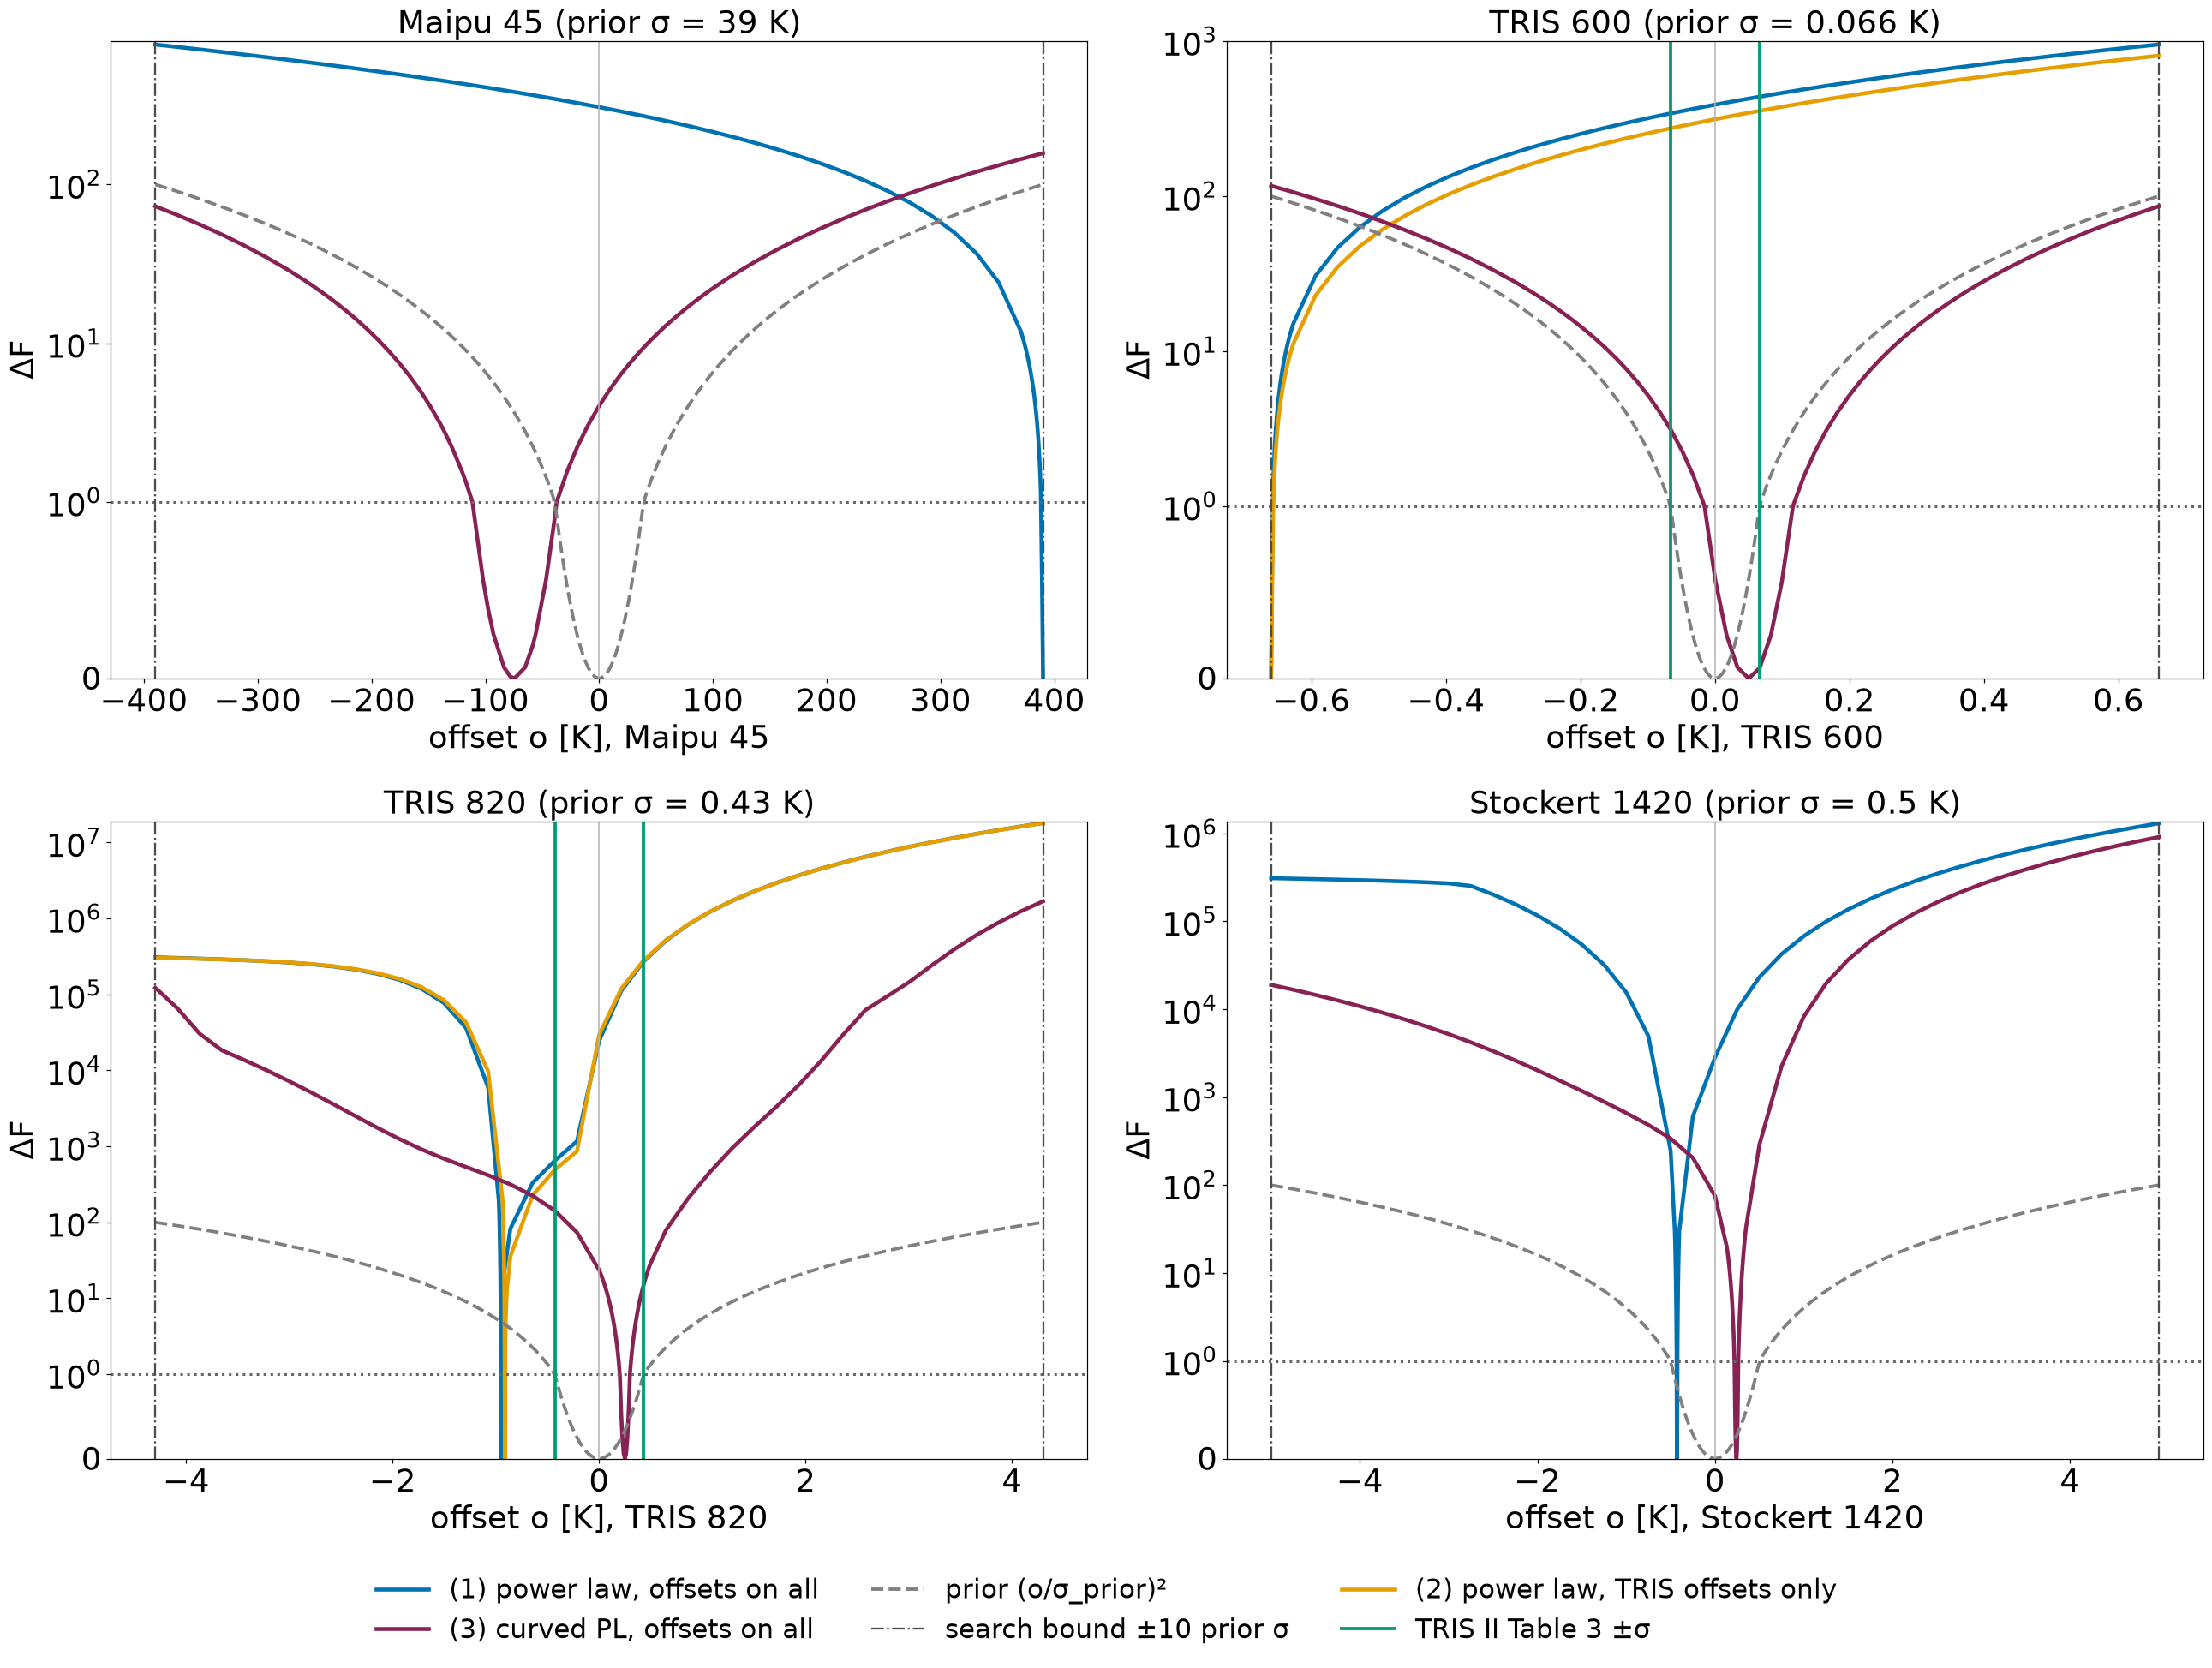

saved model_comparison/zero_level_offsets/figA_offset_profiles.png


In [9]:
CFG_STYLE = {C1: dict(color=CFG_COL["offsets"], label="(1) power law, offsets on all"),
             C2: dict(color=CFG_COL["TRIS only"], label="(2) power law, TRIS offsets only"),
             C3: dict(color=CFG_COL["curved"], label="(3) curved PL, offsets on all")}
ncol = 2; nrow = int(np.ceil(len(OFF_ALL) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(24, 9 * nrow), squeeze=False)
for a in axes.ravel()[len(OFF_ALL):]:
    a.set_visible(False)
for a, k in zip(axes.ravel(), OFF_ALL):
    xs_all = []
    for name in (C1, C2, C3):
        prob = FITS[name]["prob"]
        if k not in prob.free:
            continue
        j = prob.free.index(k)
        pr = RES[name]["profiles"][j]
        g = np.asarray(pr["grid"]) * prob.sig[j]; dF = np.asarray(pr["F"]) - min(pr["F"])
        a.plot(g, dF, lw=3, **CFG_STYLE[name]); xs_all.append(g)
    xs = np.linspace(min(x.min() for x in xs_all), max(x.max() for x in xs_all), 300)
    a.plot(xs, (xs / PRIOR[k]) ** 2, color="0.5", ls="--", lw=2.5, label="prior (o/σ_prior)²")
    a.axhline(1, color="0.4", ls=":", lw=2)
    a.axvline(0, color="0.7", lw=1)
    if k in TABLE3:
        if TABLE3[k] is None:
            a.text(0.02, 0.95, "TRIS II Table 3: not filled in\n(prior = archive zero level, fallback)", transform=a.transAxes,
                   va="top", fontsize=18, color="#009E73")
        else:
            for sgn in (-1, 1):
                a.axvline(sgn * TABLE3[k], color="#009E73", lw=2.5, label="TRIS II Table 3 ±σ" if sgn > 0 else None)
    a.set_yscale("symlog", linthresh=1.0); a.set_ylim(0, None)
    for sgn in (-1, 1):
        a.axvline(sgn * U_MAX * PRIOR[k], color="0.3", lw=1.5, ls="-.", label=f"search bound ±{U_MAX:g} prior σ" if sgn > 0 else None)
    a.set_xlabel(f"offset o [K], {SURVEYS[k]}")
    a.set_ylabel("ΔF")
    a.set_title(f"{SURVEYS[k]} (prior σ = {PRIOR[k]:g} K)")
h, l = [], []
for a in axes.ravel()[:len(OFF_ALL)]:
    for hh, ll in zip(*a.get_legend_handles_labels()):
        if ll not in l:
            h.append(hh); l.append(ll)
fig.legend(h, l, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
save(fig, "figA_offset_profiles")

### Figure B — spectral fits at three samples, with and without offsets

At the unmasked samples nearest RA 0°, 120° and 240°: the measured points with their present errors (filled), the
offset-corrected points $T - o_k$ of configuration (1) with their errors without the zero-level term (open), the
baseline power law (black) and the configuration (1) power law (blue). LWA1 has no offset, so its open and filled
points coincide. Lower panels: data − model in K, at each survey (filled: baseline; open: configuration (1), corrected
points against its model).

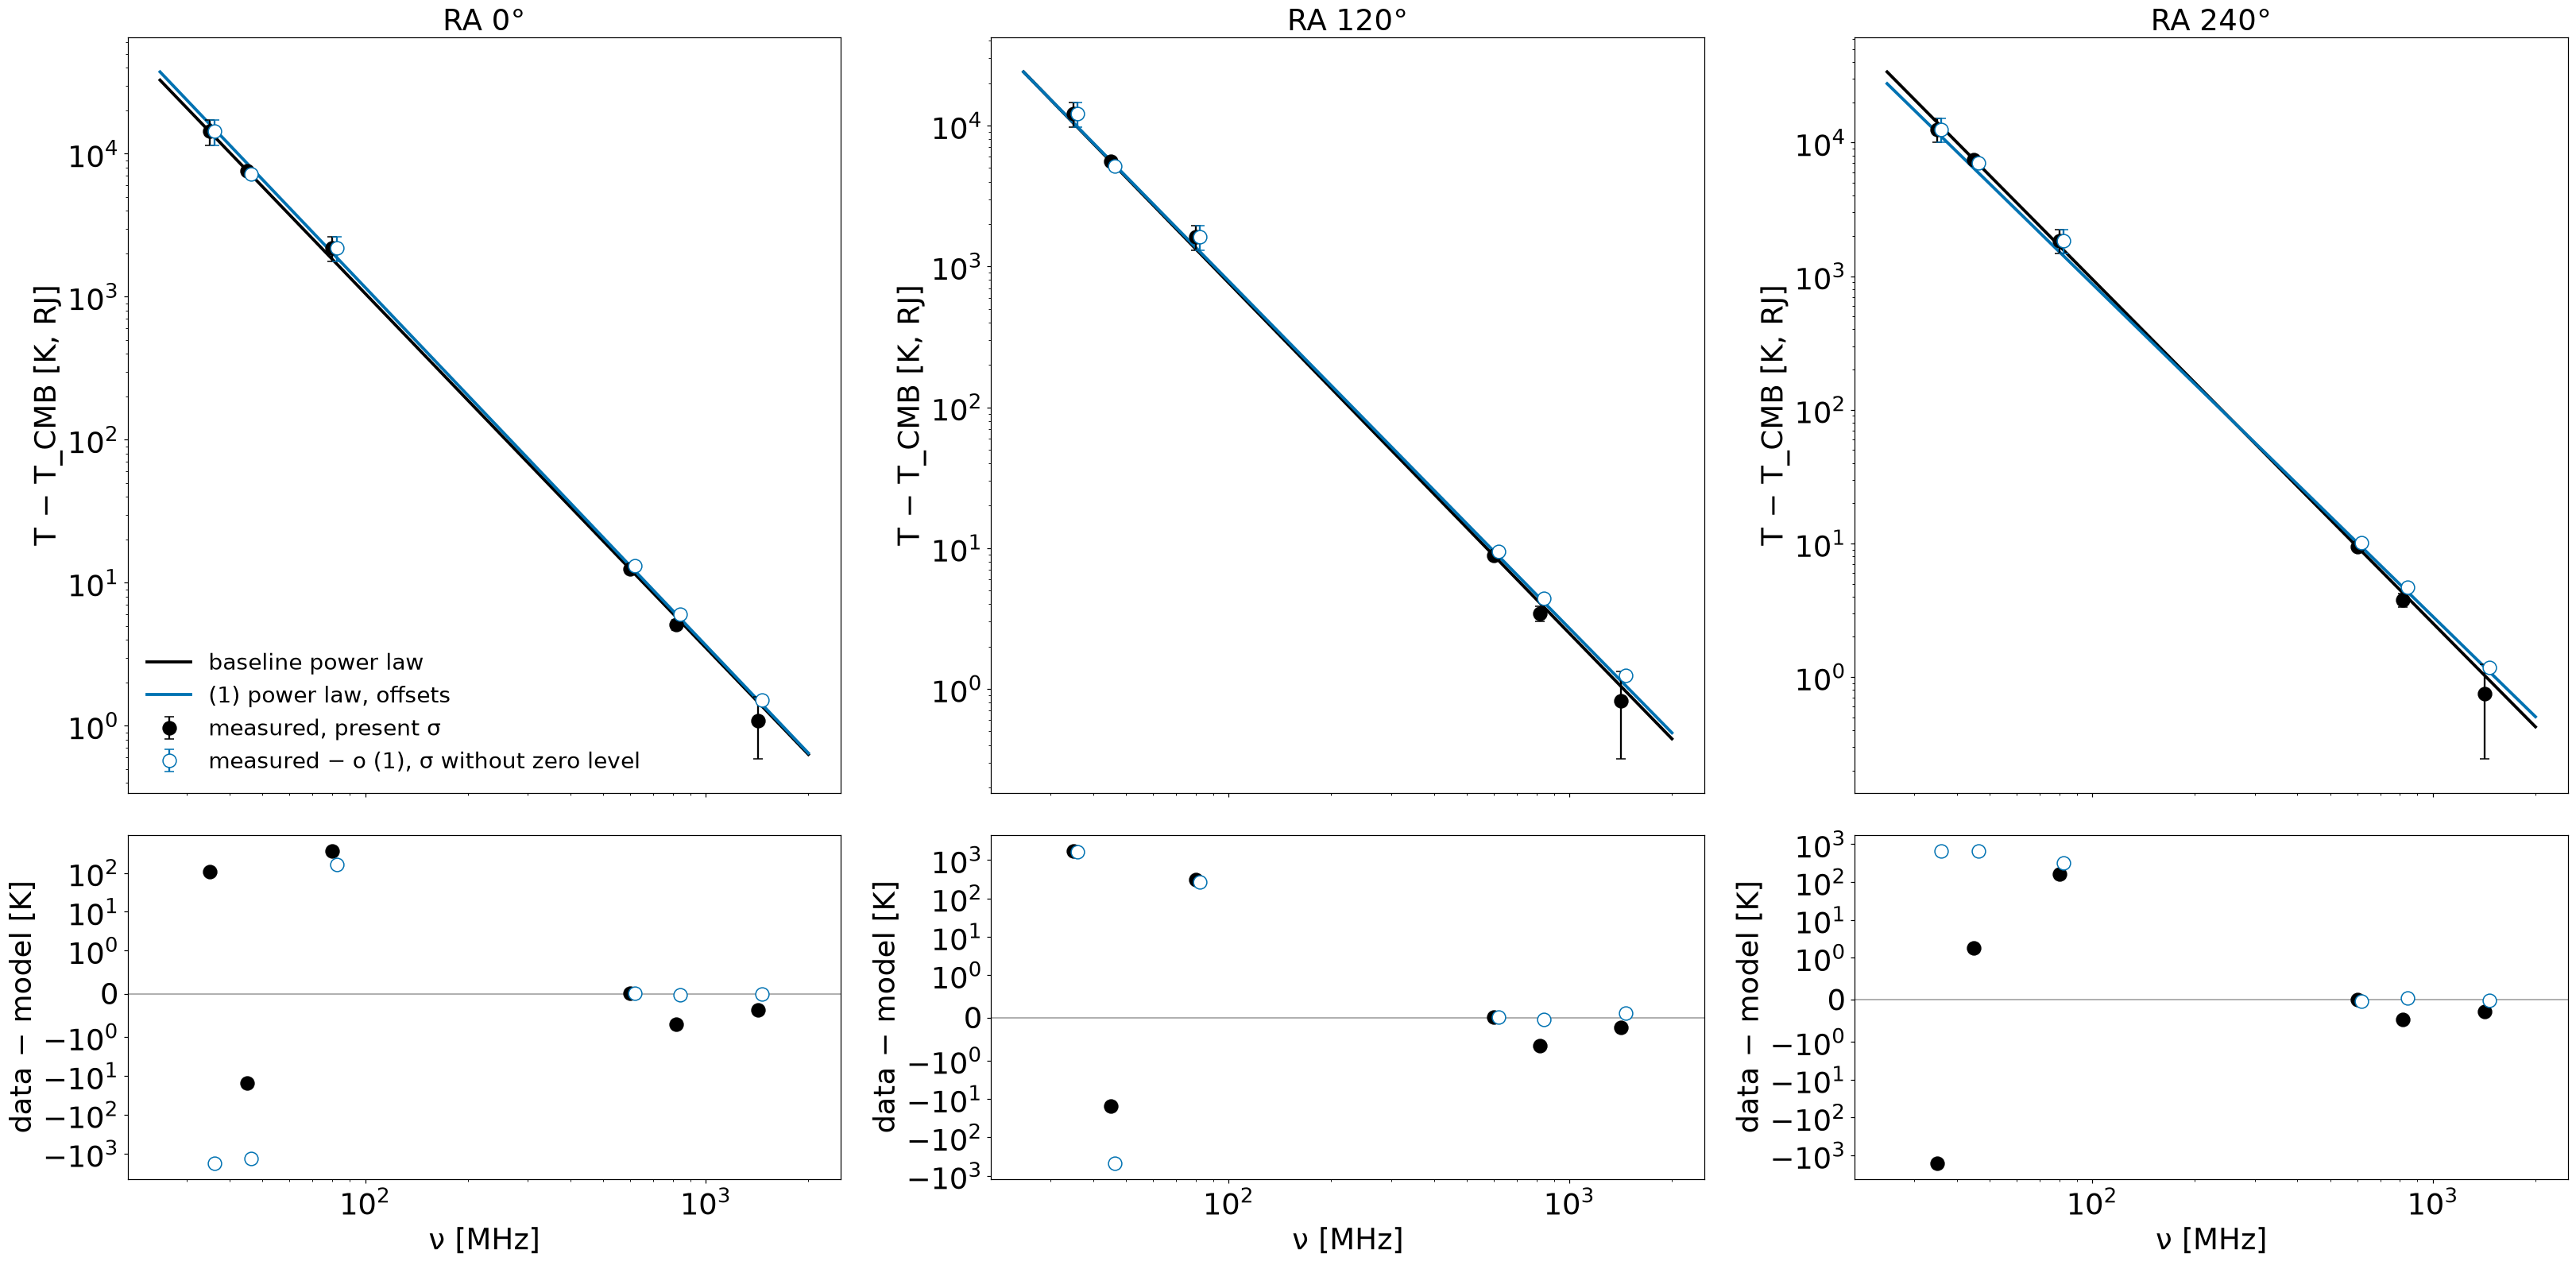

saved model_comparison/zero_level_offsets/figB_spectra_with_without_offsets.png


In [10]:
REP = [int(np.argmin(np.abs((RA[IDX] - r + 180) % 360 - 180))) for r in REP_RA]
nug = np.geomspace(25, 2000, 300); xg = np.log(nug / NU0)
fig, axes = plt.subplots(2, 3, figsize=(30, 15), gridspec_kw=dict(height_ratios=[2.2, 1]), sharex=True)
o1 = FITS[C1]["o"]
for c, i in enumerate(REP):
    a, r = axes[0, c], axes[1, c]
    for name, col, lab in ((BASE, CFG_COL["baseline"], "baseline power law"), (C1, CFG_COL["offsets"], "(1) power law, offsets")):
        p = FITS[name]["p"][i]
        a.plot(nug, np.exp(p[0] + p[1] * xg), color=col, lw=2.5, label=lab)
    a.errorbar(NU, T_DATA[i], yerr=S_TOT_M[i], fmt="o", ms=11, color="black", capsize=4, label="measured, present σ")
    a.errorbar(NU * 1.03, T_DATA[i] - o1, yerr=FITS[C1]["prob"].s[i], fmt="o", ms=11, mfc="white", color=CFG_COL["offsets"],
               capsize=4, label="measured − o (1), σ without zero level")
    a.set_xscale("log"); a.set_yscale("log")
    a.set_title(f"RA {RA[IDX][i]:.0f}°")
    a.set_ylabel("T − T_CMB [K, RJ]")
    mb = np.exp(FITS[BASE]["p"][i, 0] + FITS[BASE]["p"][i, 1] * X)
    m1 = np.exp(FITS[C1]["p"][i, 0] + FITS[C1]["p"][i, 1] * X)
    r.axhline(0, color="0.6", lw=1)
    r.plot(NU, T_DATA[i] - mb, "o", ms=11, color="black")
    r.plot(NU * 1.03, T_DATA[i] - o1 - m1, "o", ms=11, mfc="white", color=CFG_COL["offsets"])
    r.set_yscale("symlog", linthresh=1.0)
    r.set_xlabel("ν [MHz]"); r.set_ylabel("data − model [K]")
axes[0, 0].legend(frameon=False, loc="lower left", fontsize=18)
fig.tight_layout()
save(fig, "figB_spectra_with_without_offsets")

### Figure C — residuals at each survey, stacked over the samples

Data − model **in K** at each survey (one panel per survey, low to high frequency), over all unmasked samples, for the
baseline power law and curved PL and for configurations (1) and (3); with offsets, the residual is of the full
measurement model, $T^{\rm meas} - [T(\nu) + o_k]$. Boxes span the 25–75th percentiles, whiskers the 5–95th, the line
is the median. The shaded bands are the median present error (light) and the median error without the zero-level term
(dark), ±1σ. A systematic residual pattern shows up as boxes that sit away from zero; it "goes away" if the boxes with
offsets centre on zero. (Residuals are not divided by σ.)

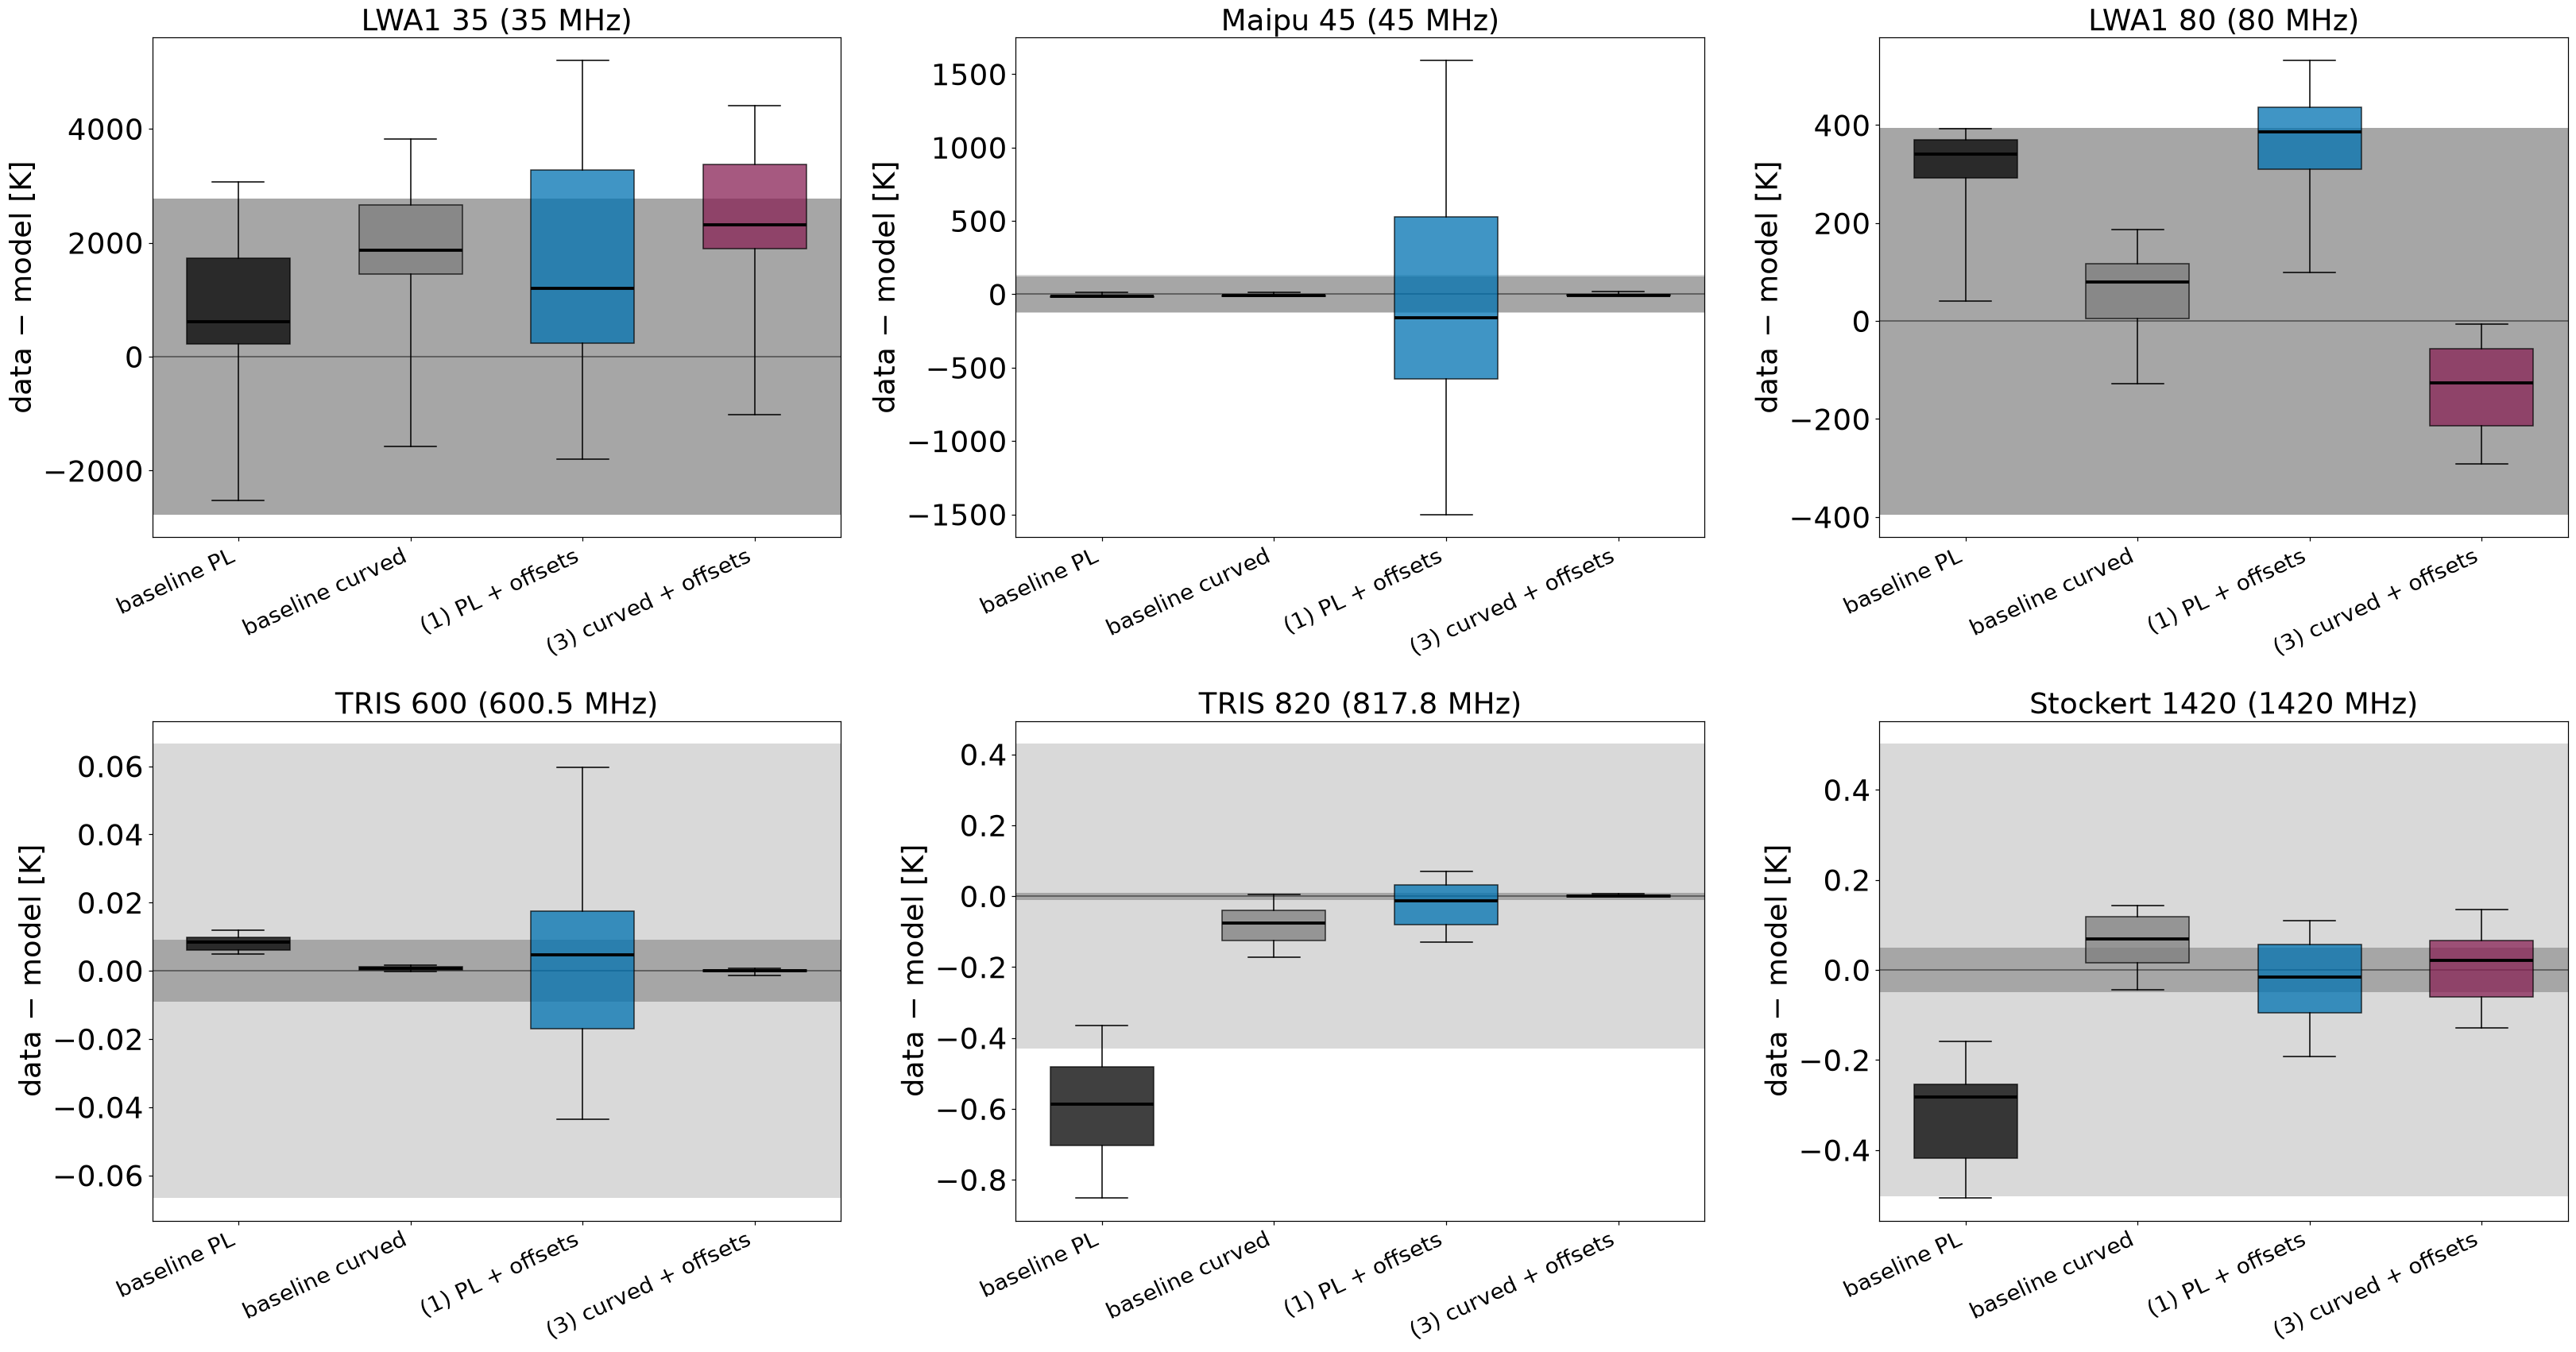

saved model_comparison/zero_level_offsets/figC_residuals_by_survey_K.png
configuration  baseline PL  baseline curved  (1) PL + offsets  (3) curved + offsets
survey                                                                             
LWA1 35           619.6232        1872.9144         1194.3607             2318.3560
Maipu 45          -15.9784          -8.9861         -161.1832               -7.1218
LWA1 80           341.0085          79.3306          386.9889             -125.5804
TRIS 600            0.0083           0.0007            0.0047                0.0001
TRIS 820           -0.5877          -0.0766           -0.0122               -0.0004
Stockert 1420      -0.2816           0.0682           -0.0162                0.0214


In [11]:
SHOW = [(BASE, "baseline PL", CFG_COL["baseline"]), (BASE_C, "baseline curved", CFG_COL["reference"]),
        (C1, "(1) PL + offsets", CFG_COL["offsets"]), (C3, "(3) curved + offsets", CFG_COL["curved"])]
def model_T(name):
    p = FITS[name]["p"]
    curv = p[:, 2:3] * X ** 2 if p.shape[1] > 2 else 0.0
    return np.exp(p[:, 0:1] + p[:, 1:2] * X + curv)
RESID = {name: T_DATA - (model_T(name) + FITS[name]["o"]) for name, _, _ in SHOW}
fig, axes = plt.subplots(2, 3, figsize=(30, 16))
rows = []
for a, j in zip(axes.ravel(), np.argsort(NU)):
    k = KEYS[j]
    a.axhspan(-np.median(S_TOT_M[:, j]), np.median(S_TOT_M[:, j]), color="0.85", lw=0, zorder=0)
    a.axhspan(-np.median(S_NOZL_M[:, j]), np.median(S_NOZL_M[:, j]), color="0.65", lw=0, zorder=0)
    a.axhline(0, color="0.3", lw=1)
    data = [RESID[name][:, j] for name, _, _ in SHOW]
    bp = a.boxplot(data, whis=(5, 95), widths=0.6, patch_artist=True, showfliers=False,
                   medianprops=dict(color="black", lw=2.5))
    for patch, (_, _, col) in zip(bp["boxes"], SHOW):
        patch.set_facecolor(col); patch.set_alpha(0.75)
    a.set_xticks(range(1, len(SHOW) + 1), [s for _, s, _ in SHOW], rotation=25, ha="right", fontsize=18)
    a.set_title(f"{SURVEYS[k]} ({NU[j]:g} MHz)")
    a.set_ylabel("data − model [K]")
    for (name, short, _), d in zip(SHOW, data):
        rows.append({"survey": SURVEYS[k], "configuration": short, "median residual [K]": np.median(d),
                     "rms residual [K]": np.sqrt(np.mean(d ** 2)), "median present σ [K]": np.median(S_TOT_M[:, j]),
                     "median σ without zero level [K]": np.median(S_NOZL_M[:, j])})
fig.tight_layout()
save(fig, "figC_residuals_by_survey_K")
tabC = pd.DataFrame(rows)
tabC.to_csv(OUT_DIR / "figC_residuals_by_survey.csv", index=False)
print(tabC.pivot(index="survey", columns="configuration", values="median residual [K]")
          .reindex([SURVEYS[KEYS[j]] for j in np.argsort(NU)])[[s for _, s, _ in SHOW]].round(4).to_string())

## Caveats

* **The offsets are constant.** Each survey's offset is one number shared by every ring sample. A zero-level error from
  the survey's own map-making could vary with position on the sky; this fit assumes it does not.
* **An offset can mimic curvature** when the frequency coverage is thin (here nothing between 80 and 600 MHz): a shift of
  the high-frequency points changes the slope between the TRIS bands and the low-frequency surveys. Table 3(b) reports how
  the curvature moves.
* **All σ are underestimates**: neighbouring samples see almost the same sky (3° apart under a ~20° beam); the ×2.6
  column is a rough correction, not an exact one. The scale (gain) terms, also common to each survey, are still treated
  as independent per point.
* **The 820 MHz TRIS prior is symmetric.** TRIS II Table 3 quotes +0.430 / −0.300 K; the prior uses the larger side,
  0.430 K, as a symmetric Gaussian, so it is wider than quoted on the negative side. Table 3's footnote a gives 0.659 K
  from the absolute calibration alone; no configuration uses it.
* **LWA1 35 and 80 get no offset**: no separate zero-level uncertainty is quoted, so their whole 20% error is kept.
* This notebook describes sizes and positions only; it does not assign causes.

## Summary

Run of 2026-11-03: 103 of 120 ring samples (Cygnus A ± 25° masked), beam-matched survey TODs. The TRIS priors are the
TRIS II Table 3 zero-level uncertainties, 0.066 K and 0.430 K (the larger side of +0.430 / −0.300 K); they equal the
zero-level terms inside `ring_sigma`, and every number is unchanged from the 2026-11-02 run. Hessian σ are underestimates
(×√(120/18) ≈ 2.6 in brackets).

* **Fitted offsets.** With the curved power law (3), every offset lies within ~2 prior widths: TRIS 600 +0.050 ± 0.066 K
  (±0.17), TRIS 820 +0.249 ± 0.049 K (±0.13), Stockert +0.241 ± 0.022 K (±0.06), Maipu −74 ± 37 K (±96), i.e. 0.76, 0.58,
  0.48 and 1.9 prior widths. With the power law (1) they do not fit inside the quoted systematics: TRIS 600 (−0.66 K) and
  Maipu (+390 K) sit at the ±10-prior-width edge of the search, so the power law's optimum is further out still; TRIS 820
  is −0.95 K (2.2 prior widths) and Stockert −0.43 K (0.86). TRIS-only offsets (2) give the same TRIS values as (1).
  LWA1 35 and 80 quote no separate zero level and get no offset.
* **820 MHz vs Table 3.** The curved fit's +0.25 K lies on the positive side, inside +0.43 K (0.58 of it). The power
  law's −0.91 to −0.95 K lies on the negative side: 2.1–2.2 times 0.43 K and 3.0–3.2 times the quoted −0.30 K side, so
  the symmetric prior is wider there than Table 3 quotes. Against footnote a's 0.659 K (absolute calibration alone),
  +0.25 K is 0.38 of it and −0.91 to −0.95 K is 1.4 times it. (The stage 1 map-making zero level
  ẑ = +0.516 ± 0.027 K comes from a different route and is shown for reference only.)
* **χ².** Taking the zero-level terms out of the per-point errors (offsets held at 0) raises χ² from 394 to 212 870 for the
  power law and from 115 to 1147 for the curved PL: TRIS is left with ~0.01 K statistical errors. Freeing the offsets
  brings the curved PL to χ² = 524 (χ²/dof 1.72; Δχ² = −622 against the same errors with offsets at 0), but the power
  law only to 12 098 (χ²/dof 29.7; TRIS-only offsets 11 624). The baseline χ² are lower because its errors are larger,
  not because it fits better.
* **Haslam gain and offset** (York, T_Haslam = g P + z). From the TRIS-only power-law prediction: g = 0.987 ± 0.072,
  z = −7.6 ± 2.4 K with the raw TRIS data; with the power-law TRIS offsets (1)/(2) g = 0.976/0.974, z = −3.9/−4.1 K
  (±1.4); with the curved-fit TRIS offsets (3) g = 0.992 ± 0.051, z = −10.1 ± 1.7 K. From the six-survey fits' A(408):
  power law g 1.055 → 1.028, z −4.8 → −5.2 K; curved PL g 0.981 → 1.011, z −5.7 → −8.8 K. g stays within its errors of 1
  throughout; across the eight rows of Table 3(a), z ranges from −10.1 K (TRIS only, offsets of (3)) to −3.9 K (TRIS
  only, offsets of (1)), a spread of 6.2 K.
* **Curvature.** Median C goes from −0.129 (baseline) to −0.149 (zero-level terms removed, offsets at 0) to −0.207 with
  the offsets free (3), and β at 408 MHz from −2.73 to −2.92: the offsets do not absorb the curvature; the curved fit
  curves more. The curved PL beats the power law by Δχ² > 2 at 59 of 103 samples in the baseline and at 102 of 103 with
  offsets.
* **Main caveat.** Once the zero levels become shared parameters, the per-point errors left (TRIS ≈ 0.01 K, Stockert ≈
  0.05 K) are smaller than the scatter of the data about either spectral model from sample to sample, so χ² stays large
  (and the power law's offsets run to the search edge). All σ are underestimates (correlated samples), the offsets are
  assumed constant along the ring, and the 820 MHz TRIS prior is symmetric although Table 3 quotes +0.430 / −0.300 K.